# 주택 가격 예측하기

메인퀘스트에 오신 것을 환영합니다!

이번 퀘스트의 목표는 여러 특성들을 종합적으로 고려하여 가장 주택 가격을 잘 예측하는 회귀모델을 만드는 것입니다.

- 예측할 값(y): SalePrice
- 평가지표: RMSE

예시 형식:
~~~
Id,SalePrice
1461,169000.1
1462,187724.1233
1463,175221
etc.
~~~

---
**개선 버전 6** — 원본 베이스라인(LinearRegression, Validation RMSE ≈ 39,487)의 흐름을 그대로 따라가면서 아래를 추가했습니다.
1. 데이터 탐색: SalePrice와 주요 변수 분포 시각화
2. 전처리: 결측치('없음' 의미 반영) · **이상치 제거** · 품질 등급 숫자화 · 조합 피처 · log 변환 · 스케일링 · 원-핫 인코딩
3. 모델 비교: 선형회귀 / Ridge / Lasso / 랜덤포레스트 / 그래디언트 부스팅 / HistGradientBoosting
4. 하이퍼파라미터 튜닝: Ridge·Lasso 규제 강도, 트리 깊이·학습률
5. 앙상블: Voting(평균) / Stacking / **가중 앙상블**(log 가격 GBR + 원래 가격 GBR + Lasso)
6. **(개선 3 추가)** 실제 평가 기준으로 Lasso 재튜닝 · 앙상블 가중치 조정 · **예측값 보정**(비싼 집을 싸게 예측하는 쏠림 펴기)
7. **(개선 4 추가)** log 변환 왜도 임계값 0.75 → **1.0** · 곡선 관계를 잡는 **SVR**을 앙상블에 추가
8. **(개선 5 추가)** 예측값 보정식을 직선 → **2차 곡선**으로 (비싼 집의 과소예측을 더 펴기, 외삽 안전장치 포함)
9. **(개선 6 추가)** 직선 보정과 2차 곡선 보정을 **50%씩 섞기** (두 보정이 서로 다른 가격대에서 틀리는 점을 이용)

| 버전 | 실제 test RMSE |
|---|---|
| 원본 | 약 90,000 |
| 개선 1 (이상치 유지, 튜닝 GBR 단일 모델) | 22,934 |
| 개선 2 (이상치 제거, 등급 숫자화, 조합 피처, Stacking) | 19,952 |
| 개선 3 (Lasso 재튜닝, 가중치 조정, 예측값 보정) | 19,500대 |
| 개선 4 (왜도 임계값 1.0, SVR 추가) | 18,600대 |
| 개선 5 (2차 곡선 보정) | 18,700대 |

### 데이터 확인 및 불러오기

In [1]:
from sklearn import set_config
set_config(display='text')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import platform

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV
from sklearn.svm import SVR
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor, StackingRegressor)
from sklearn.metrics import root_mean_squared_error
from sklearn.base import clone

RANDOM_STATE = 42   # 원본과 같은 값 → 같은 validation 데이터로 비교

# 그래프 한글 깨짐 방지 (윈도우: 맑은 고딕 / 맥: 애플고딕)
plt.rcParams['font.family'] = 'AppleGothic' if platform.system() == 'Darwin' else 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
train_df = pd.read_csv('./train.csv')
test_df = pd.read_csv('./test.csv')

In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   str    
 3   LotFrontage    950 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   str    
 6   Alley          70 non-null     str    
 7   LotShape       1168 non-null   str    
 8   LandContour    1168 non-null   str    
 9   Utilities      1168 non-null   str    
 10  LotConfig      1168 non-null   str    
 11  LandSlope      1168 non-null   str    
 12  Neighborhood   1168 non-null   str    
 13  Condition1     1168 non-null   str    
 14  Condition2     1168 non-null   str    
 15  BldgType       1168 non-null   str    
 16  HouseStyle     1168 non-null   str    
 17  OverallQual    1168 non-null   int64  
 18  OverallCond    1168

특성이 너무 많습니다! 어떻게 하면 좋을까요?

참고로 각각의 특성은 다음을 나타냅니다.

| 변수명               | 설명 (한국어)                         |
| ----------------- | -------------------------------- |
| **SalePrice**     | 주택의 판매 가격(달러). 예측해야 하는 타겟 변수     |
| **MSSubClass**    | 건물 등급(건물 종류 분류)                  |
| **MSZoning**      | 토지 용도 구분(일반적인 구역 분류)             |
| **LotFrontage**   | 도로에 접한 토지 길이 (피트 단위)             |
| **LotArea**       | 토지 면적 (평방 피트)                    |
| **Street**        | 도로 접근 방식                         |
| **Alley**         | 골목(후면 도로) 접근 방식                  |
| **LotShape**      | 토지의 전반적인 모양                      |
| **LandContour**   | 토지의 평탄도                          |
| **Utilities**     | 사용 가능한 공공시설(전기, 수도 등)            |
| **LotConfig**     | 토지 배치 형태                         |
| **LandSlope**     | 토지의 경사도                          |
| **Neighborhood**  | Ames 시 내의 물리적 위치(주변 지역)          |
| **Condition1**    | 주요 도로·철도에 대한 근접도                 |
| **Condition2**    | 두 번째 주요 도로·철도에 대한 근접도            |
| **BldgType**      | 주거 건물 유형 (단독, 다세대 등)             |
| **HouseStyle**    | 주택의 건축 양식                        |
| **OverallQual**   | 자재 및 마감 품질 종합 평가                 |
| **OverallCond**   | 주택의 전반적인 상태 평가                   |
| **YearBuilt**     | 최초 건축 연도                         |
| **YearRemodAdd**  | 리모델링/개조 연도                       |
| **RoofStyle**     | 지붕 스타일                           |
| **RoofMatl**      | 지붕 재료                            |
| **Exterior1st**   | 외장 마감재(주 재료)                     |
| **Exterior2nd**   | 외장 마감재(보조 재료, 2번째)               |
| **MasVnrType**    | 석조 베니어 타입                        |
| **MasVnrArea**    | 석조 베니어 면적 (평방 피트)                |
| **ExterQual**     | 외장재 품질 평가                        |
| **ExterCond**     | 외장재 상태 평가                        |
| **Foundation**    | 기초(Foundation) 유형                |
| **BsmtQual**      | 지하실 높이 평가                        |
| **BsmtCond**      | 지하실 상태 평가                        |
| **BsmtExposure**  | 지하실 외부 노출 여부(출입구/창문 등)           |
| **BsmtFinType1**  | 주요 지하실 마감 구역 유형                  |
| **BsmtFinSF1**    | 주요 지하실 마감 면적 (평방 피트)             |
| **BsmtFinType2**  | 보조 지하실 마감 구역 유형                  |
| **BsmtFinSF2**    | 보조 지하실 마감 면적 (평방 피트)             |
| **BsmtUnfSF**     | 미완성 지하실 면적 (평방 피트)               |
| **TotalBsmtSF**   | 지하실 전체 면적 (평방 피트)                |
| **Heating**       | 난방 시스템 종류                        |
| **HeatingQC**     | 난방 품질 및 상태                       |
| **CentralAir**    | 중앙 에어컨 설치 여부                     |
| **Electrical**    | 전기 시스템 종류                        |
| **1stFlrSF**      | 1층 면적 (평방 피트)                    |
| **2ndFlrSF**      | 2층 면적 (평방 피트)                    |
| **LowQualFinSF**  | 저품질 마감 공간 면적 (전체 층 합산)           |
| **GrLivArea**     | 지상(Above grade) 생활 공간 면적 (평방 피트) |
| **BsmtFullBath**  | 지하실 완비 욕실 수                      |
| **BsmtHalfBath**  | 지하실 반 욕실 수                       |
| **FullBath**      | 지상 완비 욕실 수                       |
| **HalfBath**      | 지상 반 욕실 수                        |
| **Bedroom**       | 지하실 제외 침실 수                      |
| **Kitchen**       | 주방 수                             |
| **KitchenQual**   | 주방 품질                            |
| **TotRmsAbvGrd**  | 지상 전체 방 개수 (욕실 제외)               |
| **Functional**    | 주택 기능성 평가                        |
| **Fireplaces**    | 벽난로 개수                           |
| **FireplaceQu**   | 벽난로 품질                           |
| **GarageType**    | 차고 위치(유형)                        |
| **GarageYrBlt**   | 차고 건축 연도                         |
| **GarageFinish**  | 차고 내부 마감 상태                      |
| **GarageCars**    | 차고 크기 (주차 가능 차량 수)               |
| **GarageArea**    | 차고 면적 (평방 피트)                    |
| **GarageQual**    | 차고 품질                            |
| **GarageCond**    | 차고 상태                            |
| **PavedDrive**    | 포장 진입로 여부                        |
| **WoodDeckSF**    | 목재 데크 면적 (평방 피트)                 |
| **OpenPorchSF**   | 오픈 현관 면적 (평방 피트)                 |
| **EnclosedPorch** | 밀폐된 현관 면적 (평방 피트)                |
| **3SsnPorch**     | 3계절용 현관 면적 (평방 피트)               |
| **ScreenPorch**   | 스크린 현관 면적 (평방 피트)                |
| **PoolArea**      | 수영장 면적 (평방 피트)                   |
| **PoolQC**        | 수영장 품질                           |
| **Fence**         | 울타리 품질                           |
| **MiscFeature**   | 기타 특수 기능                         |
| **MiscVal**       | 기타 기능의 금전적 가치                    |
| **MoSold**        | 판매 월                             |
| **YrSold**        | 판매 연도                            |
| **SaleType**      | 판매 유형                            |
| **SaleCondition** | 판매 조건                            |


In [5]:
train_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,968,20,RL,NaN,7390,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,135000
1,739,90,RL,60.0,10800,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Alloca,179000
2,696,20,RL,54.0,13811,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,176000


In [6]:
# 결측치가 있는 컬럼만, 많은 순서대로
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          1162
MiscFeature     1120
Alley           1098
Fence            941
MasVnrType       694
FireplaceQu      545
LotFrontage      218
GarageType        69
GarageYrBlt       69
GarageFinish      69
GarageQual        69
GarageCond        69
BsmtExposure      24
BsmtFinType2      24
BsmtQual          23
BsmtCond          23
BsmtFinType1      23
MasVnrArea         8
Electrical         1
dtype: int64


### 데이터 탐색 (EDA)

SalePrice의 분포와, SalePrice에 영향을 많이 주는 변수들을 그래프로 확인합니다.

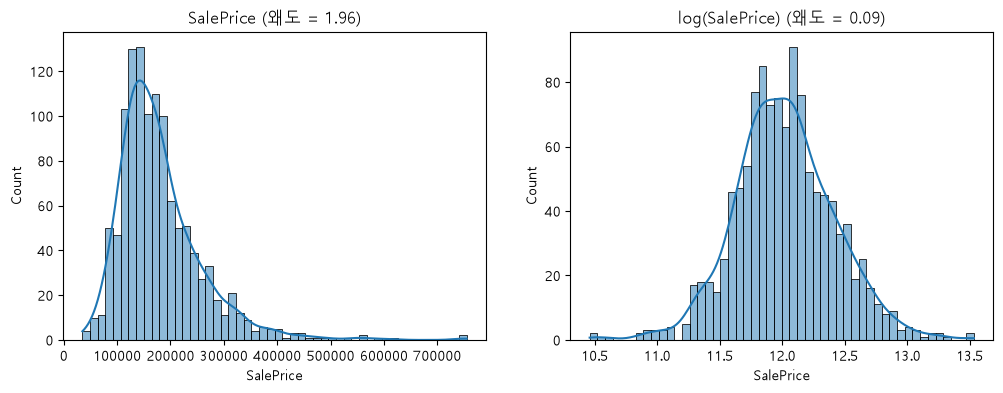

In [7]:
# SalePrice 분포 — 오른쪽으로 꼬리가 긴(비싼 집이 드물게 있는) 분포
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df['SalePrice'], bins=50, kde=True, ax=ax[0])
ax[0].set_title(f"SalePrice (왜도 = {train_df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train_df['SalePrice']), bins=50, kde=True, ax=ax[1])
ax[1].set_title(f"log(SalePrice) (왜도 = {np.log1p(train_df['SalePrice']).skew():.2f})")
plt.show()

→ SalePrice는 오른쪽 꼬리가 길고, **log를 씌우면 정규분포에 가까워집니다.**
그래서 모델은 `log(SalePrice)`를 학습하고, 예측할 때 다시 원래 가격으로 되돌립니다. (RMSE는 원래 가격 단위로 계산)

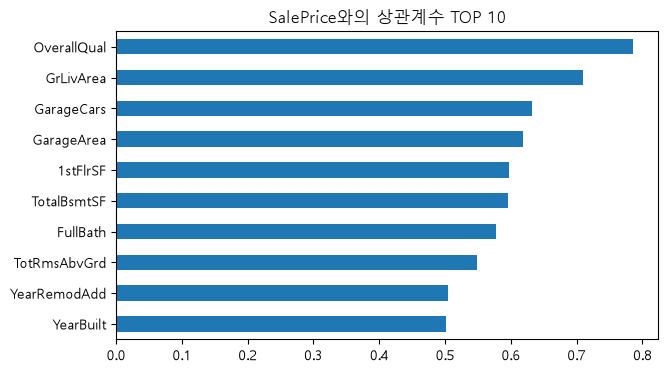

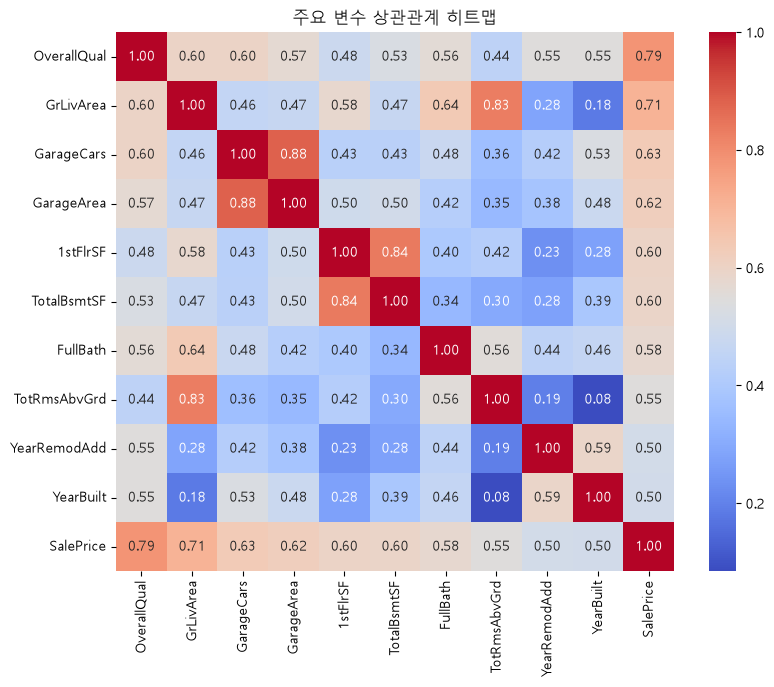

In [8]:
# SalePrice와 상관관계가 높은 숫자형 변수 TOP 10
corr = train_df.select_dtypes('number').corr()['SalePrice'].drop(['SalePrice', 'Id'])
top10 = corr.abs().sort_values(ascending=False).head(10).index

plt.figure(figsize=(7, 4))
corr[top10].sort_values().plot.barh()
plt.title('SalePrice와의 상관계수 TOP 10')
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(train_df[list(top10) + ['SalePrice']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('주요 변수 상관관계 히트맵')
plt.show()

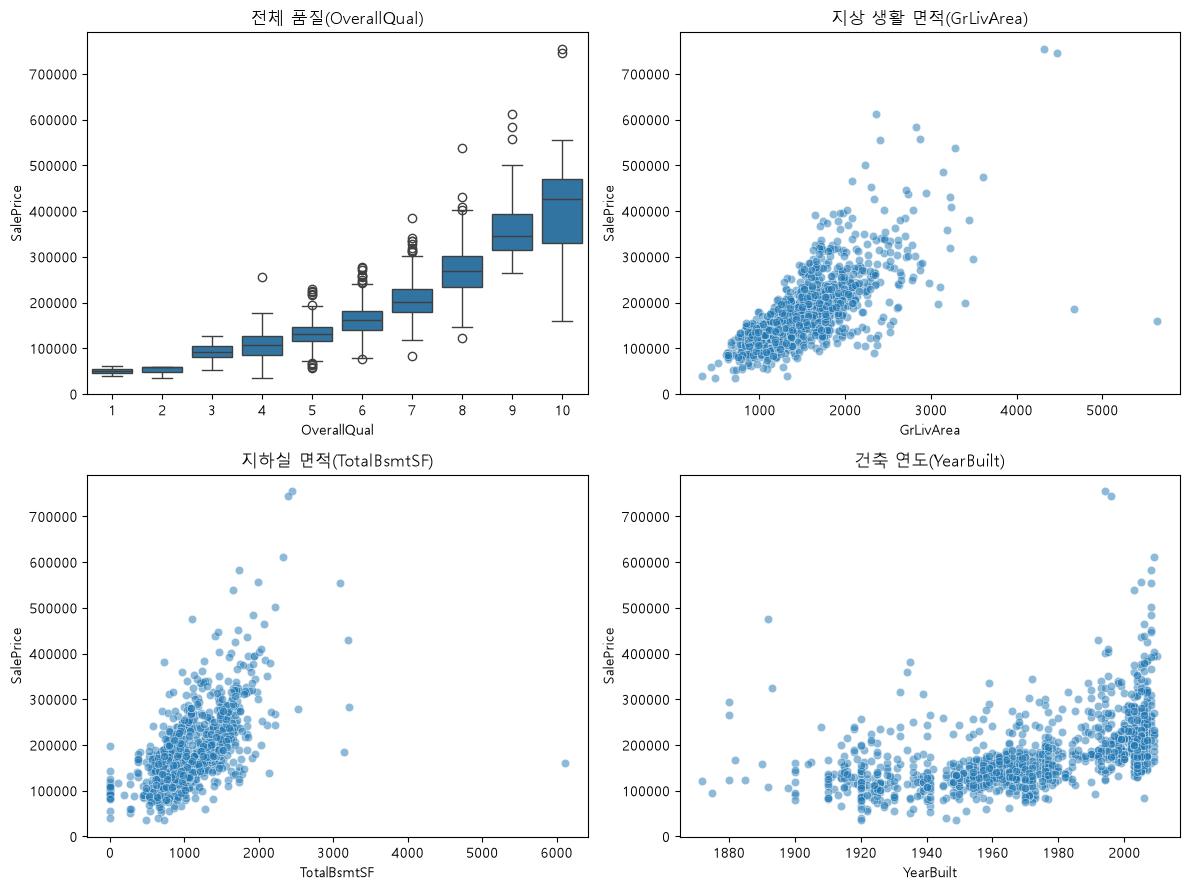

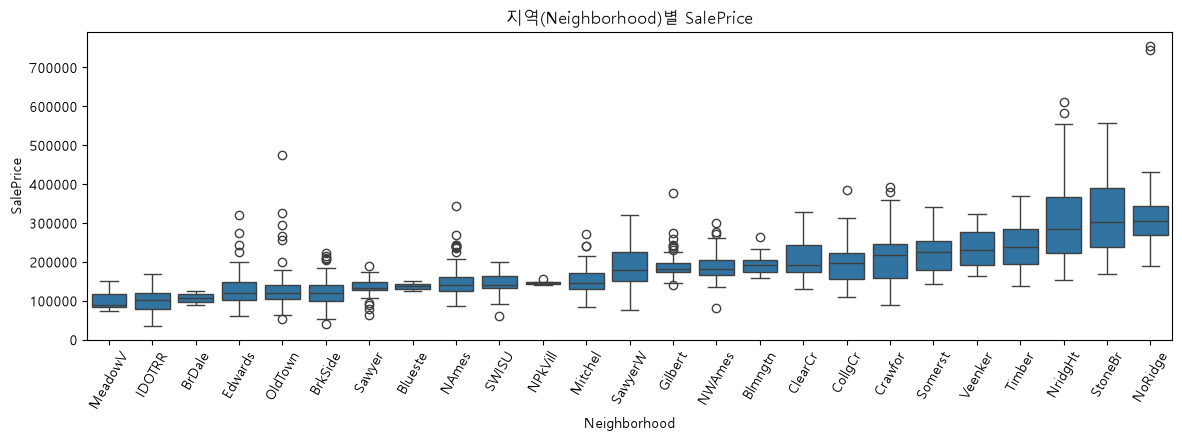

In [9]:
# 주요 변수 vs SalePrice
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
sns.boxplot(x='OverallQual', y='SalePrice', data=train_df, ax=ax[0, 0])
ax[0, 0].set_title('전체 품질(OverallQual)')
sns.scatterplot(x='GrLivArea', y='SalePrice', data=train_df, alpha=0.5, ax=ax[0, 1])
ax[0, 1].set_title('지상 생활 면적(GrLivArea)')
sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=train_df, alpha=0.5, ax=ax[1, 0])
ax[1, 0].set_title('지하실 면적(TotalBsmtSF)')
sns.scatterplot(x='YearBuilt', y='SalePrice', data=train_df, alpha=0.5, ax=ax[1, 1])
ax[1, 1].set_title('건축 연도(YearBuilt)')
plt.tight_layout()
plt.show()

# 지역별 집값 차이
order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize=(14, 4))
sns.boxplot(x='Neighborhood', y='SalePrice', data=train_df, order=order)
plt.xticks(rotation=60); plt.title('지역(Neighborhood)별 SalePrice')
plt.show()

→ **품질(OverallQual), 면적(GrLivArea, TotalBsmtSF), 건축 연도, 지역**이 집값과 관계가 큽니다.
GrLivArea 그래프 오른쪽 아래에 **면적은 매우 큰데 가격은 싼 집**(이상치)이 보입니다.

### 전처리

전처리에서 고민해야 할 것은 많습니다.

1. 결측치
2. 이상치
3. 스케일링 · 인코딩

**원본 코드의 문제점**
- 결측치를 모두 중앙값/최빈값으로 채움 → 이 데이터의 NaN은 대부분 **'없음'** 이라는 뜻 (예: PoolQC가 NaN = 수영장 없음). 최빈값으로 채우면 없는 수영장이 생김
- train과 test를 **따로** `get_dummies` → 두 데이터의 0/1 컬럼 의미가 달라져서 test 예측이 크게 틀어짐 (실제 test 점수 ≈ 9만)

**개선 방법**
- '없음' 의미의 결측치 → `'None'`(문자) / `0`(숫자), 나머지 결측치 → **train 기준** 중앙값/최빈값
- train과 test를 **합쳐서 같은 규칙으로** 인코딩 → 컬럼 의미가 항상 같음 (정답 SalePrice는 사용하지 않으므로 누수 없음)
- 품질 등급(Ex > Gd > TA > Fa > Po)은 순서가 있으므로 **5~1 숫자로** 변환 → 모델이 '높을수록 좋다'를 바로 앎
- 집값을 크게 좌우하는 **품질 × 면적** 조합 피처 추가
- 한쪽으로 치우친 숫자 변수는 log 변환, 선형 모델은 스케일링(RobustScaler) 적용

In [10]:
# 1) 결측치 — '없음'이라는 뜻인 컬럼
NONE_COLS = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'MasVnrType',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
ZERO_COLS = ['MasVnrArea', 'GarageCars', 'GarageArea',
             'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

n_train = len(train_df)
all_df = pd.concat([train_df.drop(columns=['SalePrice']), test_df], ignore_index=True)
test_ids = test_df['Id']
all_df = all_df.drop(columns=['Id'])

all_df[NONE_COLS] = all_df[NONE_COLS].fillna('None')
all_df[ZERO_COLS] = all_df[ZERO_COLS].fillna(0)
all_df['MSSubClass'] = all_df['MSSubClass'].astype(str)   # 숫자처럼 보이지만 '주택 유형 코드'

# 2) 품질 등급 → 숫자 (순서가 있는 값이라 원-핫보다 숫자가 정보를 잘 살림)
QUAL_MAP  = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
QUAL_COLS = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual',
             'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
for col in QUAL_COLS:
    all_df[col] = all_df[col].map(QUAL_MAP)

# 3) 새 피처 (면적·욕실 합계, 집 나이, 품질 × 면적)
all_df['TotalSF']   = all_df['TotalBsmtSF'] + all_df['1stFlrSF'] + all_df['2ndFlrSF']
all_df['TotalBath'] = (all_df['FullBath'] + 0.5 * all_df['HalfBath']
                       + all_df['BsmtFullBath'] + 0.5 * all_df['BsmtHalfBath'])
all_df['HouseAge']  = all_df['YrSold'] - all_df['YearBuilt']
all_df['RemodAge']  = all_df['YrSold'] - all_df['YearRemodAdd']
all_df['Qual_x_GrLiv']   = all_df['OverallQual'] * all_df['GrLivArea']   # 좋은 집이면서 넓은 집
all_df['Qual_x_TotalSF'] = all_df['OverallQual'] * all_df['TotalSF']
all_df['QualSum'] = all_df['OverallQual'] + all_df['ExterQual'] + all_df['KitchenQual']

# 4) 나머지 결측치 → train 기준 중앙값(숫자) / 최빈값(문자)
num_cols = all_df.select_dtypes(include='number').columns
cat_cols = all_df.select_dtypes(exclude='number').columns
all_df[num_cols] = all_df[num_cols].fillna(all_df.iloc[:n_train][num_cols].median())
for col in cat_cols:
    all_df[col] = all_df[col].fillna(all_df.iloc[:n_train][col].mode()[0])

print('남은 결측치:', all_df.isnull().sum().sum())

남은 결측치: 0


In [11]:
# 5) 치우친(왜도 > 1.0) 숫자 변수 log 변환 — 선형 모델(Lasso, SVR)이 특히 효과를 봄 (트리 모델은 영향 없음)
#    개선 3까지는 0.75였지만, 0.75~1.0 구간의 3개 컬럼은 log를 씌우면 오히려 정보가 왜곡됨
#     - 2ndFlrSF, BsmtUnfSF : 0(2층·미완성 지하 없음)이 많은 컬럼 → log가 0과 나머지 간격만 벌림
#     - ExterQual           : 2~5 등급 → log가 높은 등급 간격을 좁혀서 '최고 등급'의 가치를 작게 반영
#    (임계값 1.0으로 바꾸면 fold 분할 2가지에서 모두 CV가 약 270 좋아짐)
SKEW_THRESHOLD = 1.0
skewness = all_df.iloc[:n_train][num_cols].skew().abs()
skewed_cols = skewness[skewness > SKEW_THRESHOLD].index
all_df[skewed_cols] = np.log1p(all_df[skewed_cols].clip(lower=0))
print(f'log 변환한 컬럼 {len(skewed_cols)}개:', list(skewed_cols)[:10], '...')

# 6) 원-핫 인코딩 — train/test를 합친 상태에서 한 번에 → 컬럼 의미가 항상 같음
all_df = pd.get_dummies(all_df, drop_first=True).astype(float)

X = all_df.iloc[:n_train]
X_test = all_df.iloc[n_train:]
y = np.log1p(train_df['SalePrice'])   # 타깃도 log 변환

print('X:', X.shape, ' X_test:', X_test.shape)

log 변환한 컬럼 27개: ['LotFrontage', 'LotArea', 'MasVnrArea', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtFinSF1', 'BsmtFinSF2', 'TotalBsmtSF', '1stFlrSF'] ...
X: (1168, 249)  X_test: (292, 249)


이상치 개수: 2
       Id  GrLivArea  OverallQual  SalePrice
64   1299       5642           10     160000
373   524       4676           10     184750


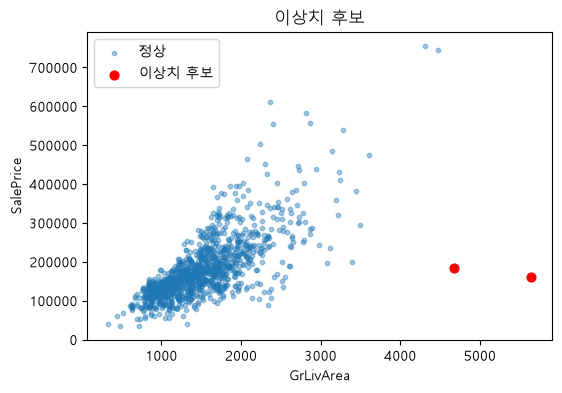

test 중 GrLivArea > 4000 인 집: 0 채


In [12]:
# 7) 이상치 확인 — 면적(GrLivArea) > 4000 인데 가격 < 30만 달러인 집
outlier = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print('이상치 개수:', outlier.sum())
print(train_df.loc[outlier, ['Id', 'GrLivArea', 'OverallQual', 'SalePrice']])

plt.figure(figsize=(6, 4))
plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], alpha=0.4, s=10, label='정상')
plt.scatter(train_df.loc[outlier, 'GrLivArea'], train_df.loc[outlier, 'SalePrice'],
            color='red', s=40, label='이상치 후보')
plt.xlabel('GrLivArea'); plt.ylabel('SalePrice'); plt.legend(); plt.title('이상치 후보')
plt.show()

# test에 이런 집(면적 4000 초과)이 있는지 확인
print('test 중 GrLivArea > 4000 인 집:', (test_df['GrLivArea'] > 4000).sum(), '채')

# 학습에서 제거 (아래 '이상치 제거 실험'에서 점수로 확인)
REMOVE_OUTLIERS = True

### 모델 설정 및 학습

- 원본과 똑같이 train의 20%를 validation으로 떼어서 **Val_RMSE**를 계산 (원본 39,487과 바로 비교 가능)
- validation 한 번은 운이 작용할 수 있어서, train 전체를 5번 다르게 나눈 **CV_RMSE**(5-fold 교차검증 평균)도 함께 봄
- 모델은 `log(SalePrice)`로 학습 → 예측값을 원래 가격으로 되돌린 뒤 RMSE 계산
- **채점할 때는 이상치 2채를 뺌**: test에는 이런 집이 한 채도 없어서, 이 2채로 채점하면 실제 test 점수와 동떨어진 결과가 나옴
  (실제로 개선 1 버전은 이상치 포함 CV가 27,485였지만 실제 test는 22,934. 이상치를 빼고 잰 CV는 24,744로 실제와 더 가까움)

In [13]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def drop_outliers(X_part, y_part):
    keep = ~outlier.loc[X_part.index]
    return X_part[keep], y_part[keep]

def rmse(X_eval, y_true_log, y_pred_log):
    """log 값을 원래 가격으로 되돌린 뒤 RMSE (test에 없는 이상치 2채는 채점에서 제외)"""
    keep = ~outlier.loc[X_eval.index].values
    return root_mean_squared_error(np.expm1(y_true_log[keep]), np.expm1(y_pred_log[keep]))

def evaluate(model, remove_outliers=REMOVE_OUTLIERS):
    """Val_RMSE와 5-fold CV_RMSE(평균, 표준편차) 계산. 이상치 제거는 학습 데이터에만 적용"""
    Xa, ya = drop_outliers(X_train, y_train) if remove_outliers else (X_train, y_train)
    val = rmse(X_val, y_val, clone(model).fit(Xa, ya).predict(X_val))
    cv = []
    for tr, va in kf.split(X):
        Xa, ya = X.iloc[tr], y.iloc[tr]
        if remove_outliers:
            Xa, ya = drop_outliers(Xa, ya)
        cv.append(rmse(X.iloc[va], y.iloc[va], clone(model).fit(Xa, ya).predict(X.iloc[va])))
    return val, np.mean(cv), np.std(cv)

results = []   # 모든 실험 결과를 여기에 모아서 마지막에 비교
def record(stage, name, model):
    val, cv_mean, cv_std = evaluate(model)
    results.append({'단계': stage, '모델': name, 'Val_RMSE': val, 'CV_RMSE': cv_mean, 'CV_std': cv_std})
    print(f'{name:22s} Val_RMSE = {val:>9,.0f}   CV_RMSE = {cv_mean:>9,.0f} (± {cv_std:,.0f})')

In [14]:
# 기본 모델 6개 (선형 모델은 스케일링 포함)
base_models = {
    'LinearRegression': make_pipeline(RobustScaler(), LinearRegression()),
    'Ridge':            make_pipeline(RobustScaler(), Ridge(alpha=1.0)),
    'Lasso':            make_pipeline(RobustScaler(), Lasso(alpha=0.001, max_iter=50000)),
    'RandomForest':     RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    'GradientBoosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

for name, model in base_models.items():
    record('1.기본', name, model)

LinearRegression       Val_RMSE =    20,870   CV_RMSE =    23,670 (± 2,688)
Ridge                  Val_RMSE =    18,627   CV_RMSE =    22,099 (± 2,311)
Lasso                  Val_RMSE =    18,330   CV_RMSE =    22,936 (± 2,678)
RandomForest           Val_RMSE =    24,069   CV_RMSE =    26,801 (± 3,520)
GradientBoosting       Val_RMSE =    22,455   CV_RMSE =    25,457 (± 2,360)
HistGradientBoosting   Val_RMSE =    23,722   CV_RMSE =    25,756 (± 1,407)


In [15]:
print('원본 베이스라인 Val_RMSE ≈ 39,487')
base_df = pd.DataFrame(results)
base_df.sort_values('CV_RMSE').round(0)

원본 베이스라인 Val_RMSE ≈ 39,487


,단계,모델,Val_RMSE,CV_RMSE,CV_std
1,1.기본,Ridge,18627.0,22099.0,2311.0
2,1.기본,Lasso,18330.0,22936.0,2678.0
0,1.기본,LinearRegression,20870.0,23670.0,2688.0
4,1.기본,GradientBoosting,22455.0,25457.0,2360.0
5,1.기본,HistGradientBoosting,23722.0,25756.0,1407.0
3,1.기본,RandomForest,24069.0,26801.0,3520.0


### 이상치 제거 실험

이상치를 지우면 점수가 좋아지는지 Ridge와 GradientBoosting으로 비교합니다.
(이상치는 **학습 데이터에서만** 지우고, 평가 데이터는 그대로 둠)

In [16]:
for name in ['Ridge', 'GradientBoosting']:
    keep  = evaluate(base_models[name], remove_outliers=False)
    remove = evaluate(base_models[name], remove_outliers=True)
    print(f'{name:18s} 유지: CV_RMSE = {keep[1]:,.0f}   제거: CV_RMSE = {remove[1]:,.0f}')

Ridge              유지: CV_RMSE = 24,608   제거: CV_RMSE = 22,099
GradientBoosting   유지: CV_RMSE = 25,617   제거: CV_RMSE = 25,457


→ test와 같은 조건(이상치 없이 채점)에서는 **제거하는 쪽이 두 모델 모두 더 좋습니다.** 그래서 `REMOVE_OUTLIERS = True`로 둡니다.

💡 개선 1 버전에서는 이상치까지 포함해서 채점했기 때문에 '제거하면 나빠진다'는 반대 결론이 나왔습니다.
**평가 방법을 실제 test 상황에 맞추는 것**이 그만큼 중요합니다.

### 하이퍼파라미터 튜닝

- **Ridge / Lasso**: 규제 강도 `alpha` (클수록 계수를 더 작게 눌러서 과적합 방지)
- **RandomForest**: 트리 깊이 `max_depth`, 분기에 쓰는 특성 비율 `max_features`
- **GradientBoosting**: 학습률 `learning_rate`, 트리 깊이 `max_depth`, 트리 개수 `n_estimators`

`GridSearchCV`로 train 데이터 안에서 5-fold 교차검증하며 가장 좋은 값을 찾습니다.

In [17]:
def tune(name, model, params):
    gs = GridSearchCV(model, params, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    Xa, ya = drop_outliers(X_train, y_train) if REMOVE_OUTLIERS else (X_train, y_train)
    gs.fit(Xa, ya)
    print(f'[{name}] 최적 파라미터: {gs.best_params_}')
    record('2.튜닝', name, gs.best_estimator_)
    return gs.best_estimator_

tuned = {}
tuned['Ridge'] = tune('Ridge', make_pipeline(RobustScaler(), Ridge()),
                      {'ridge__alpha': [1, 3, 10, 20, 30, 50]})
tuned['Lasso'] = tune('Lasso', make_pipeline(RobustScaler(), Lasso(max_iter=50000)),
                      {'lasso__alpha': [0.0003, 0.0005, 0.001, 0.003]})

[Ridge] 최적 파라미터: {'ridge__alpha': 10}
Ridge                  Val_RMSE =    17,970   CV_RMSE =    22,190 (± 2,420)
[Lasso] 최적 파라미터: {'lasso__alpha': 0.0003}
Lasso                  Val_RMSE =    17,919   CV_RMSE =    22,103 (± 2,559)


In [18]:
tuned['RandomForest'] = tune('RandomForest',
    RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    {'max_depth': [None, 15, 25], 'max_features': [0.3, 0.5, 1.0]})

[RandomForest] 최적 파라미터: {'max_depth': 25, 'max_features': 0.5}
RandomForest           Val_RMSE =    23,688   CV_RMSE =    25,684 (± 2,137)


In [19]:
# 학습률을 낮추면 트리 개수를 늘려야 함 → 같이 조정 (몇 분 걸릴 수 있음)
tuned['GradientBoosting'] = tune('GradientBoosting',
    GradientBoostingRegressor(subsample=0.8, max_features='sqrt', random_state=RANDOM_STATE),
    {'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4], 'n_estimators': [500, 1000]})

[GradientBoosting] 최적 파라미터: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 1000}
GradientBoosting       Val_RMSE =    19,663   CV_RMSE =    22,292 (± 2,426)


In [20]:
tuned['HistGradientBoosting'] = tune('HistGradientBoosting',
    HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    {'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 5, None], 'max_iter': [300, 600]})

[HistGradientBoosting] 최적 파라미터: {'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 600}
HistGradientBoosting   Val_RMSE =    21,729   CV_RMSE =    25,195 (± 2,018)


### 앙상블

성격이 다른 모델(선형 + 트리)은 틀리는 방식이 달라서, 섞으면 서로의 실수를 보완해줍니다.
- **Voting**: 여러 모델 예측값의 평균
- **Stacking**: 각 모델의 예측값을 입력으로, 최종 모델(RidgeCV)이 가장 좋은 조합 비율을 학습
- **가중 앙상블**: 잘하는 모델에 더 큰 비중 (GBR log 40% + GBR 원래가격 40% + Lasso 20%)

💡 **원래 가격으로 학습한 GBR을 섞는 이유**
log 가격으로 학습하면 비싼 집/싼 집을 '비율'로 똑같이 봅니다. 그런데 평가지표 RMSE는 **원래 가격 단위**라서
오차 금액이 큰 **비싼 집에서 점수가 크게 갈립니다.** 원래 가격으로 학습한 모델은 비싼 집 오차를 더 신경 쓰므로, 섞으면 서로 보완됩니다.

In [21]:
from sklearn.compose import TransformedTargetRegressor

# 원래 가격으로 학습하는 GBR — 입력 y가 log라서, expm1로 원래 가격으로 바꿔 학습하고 예측은 다시 log로 돌려줌
gbr_raw = TransformedTargetRegressor(regressor=clone(tuned['GradientBoosting']),
                                     func=np.expm1, inverse_func=np.log1p, check_inverse=False)
record('2.튜닝', 'GradientBoosting(원래가격)', gbr_raw)

ens_members = [(name, tuned[name]) for name in ['Ridge', 'Lasso', 'GradientBoosting', 'HistGradientBoosting']]

ensembles = {
    'Voting(선형+부스팅)': VotingRegressor(ens_members),
    'Voting(전체 5개)':    VotingRegressor(ens_members + [('RandomForest', tuned['RandomForest'])]),
    'Stacking':           StackingRegressor(ens_members, final_estimator=RidgeCV(), cv=5, n_jobs=-1),
    '가중(GBR+GBR원래+Lasso)': VotingRegressor([('gbr_log', tuned['GradientBoosting']),
                                                ('gbr_raw', gbr_raw),
                                                ('lasso', tuned['Lasso'])], weights=[0.4, 0.4, 0.2]),
}
for name, model in ensembles.items():
    record('3.앙상블', name, model)

GradientBoosting(원래가격) Val_RMSE =    19,161   CV_RMSE =    21,980 (± 2,173)
Voting(선형+부스팅)         Val_RMSE =    18,070   CV_RMSE =    21,890 (± 2,459)
Voting(전체 5개)          Val_RMSE =    18,475   CV_RMSE =    22,021 (± 2,333)
Stacking               Val_RMSE =    18,153   CV_RMSE =    21,369 (± 2,293)
가중(GBR+GBR원래+Lasso)    Val_RMSE =    18,321   CV_RMSE =    21,434 (± 2,339)


### 개선 3: 실제 평가 기준으로 다시 맞추기

**① Lasso 재튜닝** — 위의 GridSearchCV는 **log 가격 기준** RMSE로 최적값을 골랐습니다.
실제 평가는 **원래 가격 기준** RMSE이므로, 같은 `evaluate()`(원래 가격 RMSE, 이상치 제외 채점)로 alpha를 다시 비교합니다.

> GBR도 같은 방식으로 19가지 설정을 비교해봤지만, 튜닝에 쓴 fold 분할에서만 좋아지고 **다른 분할에서는 오히려 나빠져서**
> (여러 후보 중 운 좋게 1등한 '고르기 과적합') 기존 설정을 유지했습니다.

In [22]:
lasso_scores = {}
for a in [0.0001, 0.0002, 0.0003, 0.0005]:
    val, cv_mean, cv_std = evaluate(make_pipeline(RobustScaler(), Lasso(alpha=a, max_iter=50000)))
    lasso_scores[a] = cv_mean
    print(f'Lasso alpha={a:<7}  Val_RMSE = {val:>9,.0f}   CV_RMSE = {cv_mean:>9,.0f} (± {cv_std:,.0f})')

best_alpha = min(lasso_scores, key=lasso_scores.get)
lasso_final = make_pipeline(RobustScaler(), Lasso(alpha=best_alpha, max_iter=50000))
print('→ 실제 평가 기준 최적 alpha:', best_alpha)

Lasso alpha=0.0001   Val_RMSE =    18,244   CV_RMSE =    21,939 (± 2,491)
Lasso alpha=0.0002   Val_RMSE =    17,984   CV_RMSE =    21,910 (± 2,560)
Lasso alpha=0.0003   Val_RMSE =    17,919   CV_RMSE =    22,103 (± 2,559)
Lasso alpha=0.0005   Val_RMSE =    17,976   CV_RMSE =    22,300 (± 2,510)
→ 실제 평가 기준 최적 alpha: 0.0002


**② 오차 분석** — 어떤 집을 잘 못 맞추는지 가격대별로 확인합니다. (5-fold 교차검증 예측값 사용)

,집수,RMSE,평균오차,전체오차중비중
가격대,,,,
~10만,92,20723.0,11552.0,0.07
10~15만,391,14876.0,1359.0,0.16
15~20만,341,13433.0,378.0,0.11
20~30만,255,21285.0,-2793.0,0.21
30~40만,66,35584.0,-14109.0,0.15
40만~,21,89898.0,-55622.0,0.31


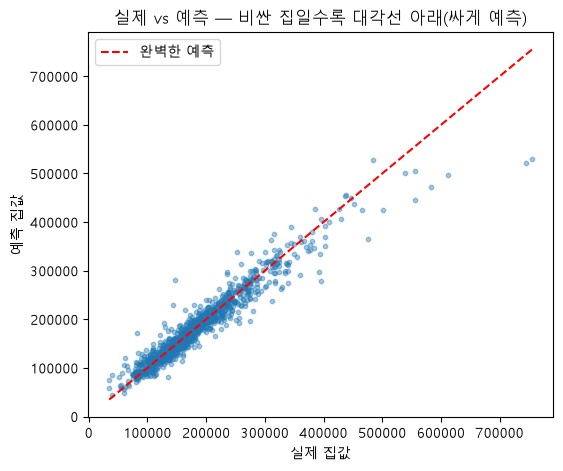

In [23]:
from sklearn.model_selection import cross_val_predict

Xa, ya = drop_outliers(X, y)
oof_pred = cross_val_predict(ensembles['가중(GBR+GBR원래+Lasso)'], Xa, ya, cv=kf)

err_df = pd.DataFrame({'실제': np.expm1(ya), '예측': np.expm1(oof_pred)})
err_df['오차'] = err_df['예측'] - err_df['실제']
err_df['가격대'] = pd.cut(err_df['실제'], [0, 100000, 150000, 200000, 300000, 400000, np.inf],
                       labels=['~10만', '10~15만', '15~20만', '20~30만', '30~40만', '40만~'])
summary = err_df.groupby('가격대', observed=True).agg(
    집수=('오차', 'size'),
    RMSE=('오차', lambda e: np.sqrt((e ** 2).mean())),
    평균오차=('오차', 'mean'),
    전체오차중비중=('오차', lambda e: (e ** 2).sum() / (err_df['오차'] ** 2).sum()))
display(summary.round({'RMSE': 0, '평균오차': 0, '전체오차중비중': 2}))

plt.figure(figsize=(6, 5))
plt.scatter(err_df['실제'], err_df['예측'], alpha=0.4, s=10)
lims = [err_df[['실제', '예측']].min().min(), err_df[['실제', '예측']].max().max()]
plt.plot(lims, lims, 'r--', label='완벽한 예측')
plt.xlabel('실제 집값'); plt.ylabel('예측 집값'); plt.legend()
plt.title('실제 vs 예측 — 비싼 집일수록 대각선 아래(싸게 예측)')
plt.show()

→ **싼 집은 비싸게(평균오차 +), 비싼 집은 싸게(평균오차 −)** 예측합니다. 예측이 평균 쪽으로 쏠리는 현상입니다.
40만 달러 이상 집은 몇 채 안 되지만 전체 오차에서 큰 비중을 차지합니다.

**③ 예측값 보정** — 학습 데이터 안에서 다시 교차검증한 예측값으로 `실제 = a + b × 예측` 관계를 학습해서, 쏠린 예측을 펴줍니다.
- b가 1보다 크면 '평균에서 멀어지는 쪽'으로 늘려줌 → 비싼 집은 더 비싸게, 싼 집은 더 싸게
- 보정식은 **학습 데이터로만** 만들기 때문에(평가 fold는 사용 안 함) 점수가 부풀려지지 않음

**④ 가중치 조정** — 여러 fold 분할에서 비교했을 때 Lasso 비중을 늘린 **0.2 / 0.4 / 0.4**가 일관되게 더 좋았습니다.

In [24]:
from sklearn.base import BaseEstimator, RegressorMixin

class CalibratedRegressor(BaseEstimator, RegressorMixin):
    """모델 예측값의 쏠림을 보정 (log 가격을 입력받아 log 가격을 예측)"""
    def __init__(self, estimator, cv=5):
        self.estimator = estimator
        self.cv = cv

    def fit(self, X, y):
        # 1) 학습 데이터 안에서 교차검증 예측 → 2) 원래 가격 단위로 '실제 = a + b × 예측' 학습 → 3) 전체로 모델 학습
        inner = KFold(n_splits=self.cv, shuffle=True, random_state=RANDOM_STATE)
        p = cross_val_predict(self.estimator, X, y, cv=inner)
        self.calib_ = LinearRegression().fit(np.expm1(p).reshape(-1, 1), np.expm1(y))
        self.model_ = clone(self.estimator).fit(X, y)
        return self

    def predict(self, X):
        p = np.expm1(self.model_.predict(X)).reshape(-1, 1)
        return np.log1p(np.clip(self.calib_.predict(p), 1, None))

weighted_new = VotingRegressor([('gbr_log', tuned['GradientBoosting']),
                                ('gbr_raw', gbr_raw),
                                ('lasso', lasso_final)], weights=[0.2, 0.4, 0.4])

ensembles['가중 v3 (Lasso 재튜닝 + 0.2/0.4/0.4)'] = weighted_new
record('4.개선3', '가중 v3 (Lasso 재튜닝 + 0.2/0.4/0.4)', weighted_new)

ensembles['가중 v3 + 예측값 보정'] = CalibratedRegressor(weighted_new)
record('4.개선3', '가중 v3 + 예측값 보정', ensembles['가중 v3 + 예측값 보정'])

calib_check = CalibratedRegressor(weighted_new).fit(*drop_outliers(X, y))
print(f"\n보정식: 실제 ≈ {calib_check.calib_.intercept_:,.0f} + {calib_check.calib_.coef_[0]:.3f} × 예측")

가중 v3 (Lasso 재튜닝 + 0.2/0.4/0.4) Val_RMSE =    17,758   CV_RMSE =    21,084 (± 2,358)
가중 v3 + 예측값 보정         Val_RMSE =    18,804   CV_RMSE =    20,805 (± 1,787)

보정식: 실제 ≈ -8,112 + 1.050 × 예측


### 개선 4: 새로운 종류의 모델(SVR) 추가

앙상블은 **서로 다른 방식으로 틀리는 모델**을 섞을 때 좋아집니다. 지금까지는 선형(Lasso) + 트리(GBR) 두 종류였습니다.
- **SVR**(Support Vector Regression): 작은 오차(epsilon 이내)는 무시하고 큰 오차를 줄이도록 학습, RBF 커널로 **곡선 관계**도 잡음
- 비교 실험 결과 (fold 분할 2가지 평균): SVR(C=50) 단독 CV ≈ 21,861 → 지금까지 **단독 모델 중 최고**
- 같은 실험에서 ElasticNet은 Lasso와 성격이 같아 효과가 없었고, KernelRidge는 SVR보다 효과가 작았음

가중치: 기존 v3 비율(0.2 / 0.4 / 0.4)을 70%로 줄이고 SVR 30% → **GBR 0.14 / GBR원래 0.28 / Lasso 0.28 / SVR 0.30**

In [25]:
svr = make_pipeline(RobustScaler(), SVR(C=50, epsilon=0.008, gamma=0.0002))
record('4.개선4', 'SVR', svr)

weighted_v4 = VotingRegressor([('gbr_log', tuned['GradientBoosting']),
                               ('gbr_raw', gbr_raw),
                               ('lasso', lasso_final),
                               ('svr', svr)], weights=[0.14, 0.28, 0.28, 0.30])

ensembles['가중 v4 (+SVR 30%)'] = weighted_v4
record('4.개선4', '가중 v4 (+SVR 30%)', weighted_v4)

ensembles['가중 v4 + 예측값 보정'] = CalibratedRegressor(weighted_v4)
record('4.개선4', '가중 v4 + 예측값 보정', ensembles['가중 v4 + 예측값 보정'])

SVR                    Val_RMSE =    17,312   CV_RMSE =    21,212 (± 2,376)
가중 v4 (+SVR 30%)       Val_RMSE =    17,219   CV_RMSE =    20,845 (± 2,398)
가중 v4 + 예측값 보정         Val_RMSE =    18,317   CV_RMSE =    20,538 (± 1,825)


### 개선 5: 예측값 보정을 2차 곡선으로

개선 4의 오차를 가격대별로 다시 보면, 직선 보정 후에도 **40만 달러 이상 집을 평균 약 5만 8천 달러 싸게** 예측합니다 (21채가 전체 오차의 27%).
직선(`실제 = a + b × 예측`)은 모든 가격대를 같은 비율로 늘리기 때문에, 비쌀수록 더 크게 싸게 예측하는 쏠림을 다 펴지 못합니다.

→ 보정식을 **`실제 = a + b × 예측 + c × 예측²`** 로 바꿔서, 비싸게 예측한 집일수록 더 많이 올려줍니다.
- **외삽 안전장치**: 학습 데이터의 가장 비싼 예측값을 넘으면 곡선 대신 그 지점의 기울기로 **직선 연장** → 처음 보는 고가 주택에서 값이 치솟지 않도록
- 보정식은 여전히 **학습 데이터 안의 교차검증 예측으로만** 만듦 (평가 fold 사용 안 함)
- 비교 실험 (fold 분할 2가지): 직선 보정 20,918 → 2차 곡선 보정 **20,299** (두 분할 모두 개선)
- 주의: 개선은 주로 40만 달러 이상 집에서 나오므로, test에 비싼 집이 적으면 효과가 CV보다 작을 수 있습니다

In [26]:
class QuadCalibratedRegressor(CalibratedRegressor):
    """예측값 보정을 2차 곡선으로 (학습 범위를 넘으면 직선 연장)"""
    @staticmethod
    def _f(p):
        return np.c_[p, p ** 2 / 1e6]   # 가격² 은 너무 커서 100만으로 나눔

    def fit(self, X, y):
        inner = KFold(n_splits=self.cv, shuffle=True, random_state=RANDOM_STATE)
        p = np.expm1(cross_val_predict(self.estimator, X, y, cv=inner))
        self.calib_ = LinearRegression().fit(self._f(p), np.expm1(y))
        self.hi_ = p.max()                                                  # 학습에서 본 가장 비싼 예측값
        self.hi_val_ = self.calib_.predict(self._f(np.array([self.hi_])))[0]
        self.slope_ = self.calib_.coef_[0] + 2 * self.calib_.coef_[1] * self.hi_ / 1e6   # 그 지점의 기울기
        self.model_ = clone(self.estimator).fit(X, y)
        return self

    def predict(self, X):
        p = np.expm1(self.model_.predict(X))
        out = np.where(p <= self.hi_,
                       self.calib_.predict(self._f(np.minimum(p, self.hi_))),
                       self.hi_val_ + self.slope_ * (p - self.hi_))
        return np.log1p(np.clip(out, 1, None))

ensembles['가중 v4 + 2차 곡선 보정'] = QuadCalibratedRegressor(weighted_v4)
record('4.개선5', '가중 v4 + 2차 곡선 보정', ensembles['가중 v4 + 2차 곡선 보정'])

가중 v4 + 2차 곡선 보정       Val_RMSE =    18,090   CV_RMSE =    19,713 (± 1,725)


직선 보정: 실제 ≈ -9,245 + 1.056 × 예측
2차 보정: 실제 ≈ 22,630 + 0.731 × 예측 + 0.7064 × 예측² / 1,000,000
직선 연장 시작점: 예측 563,426 달러 이상


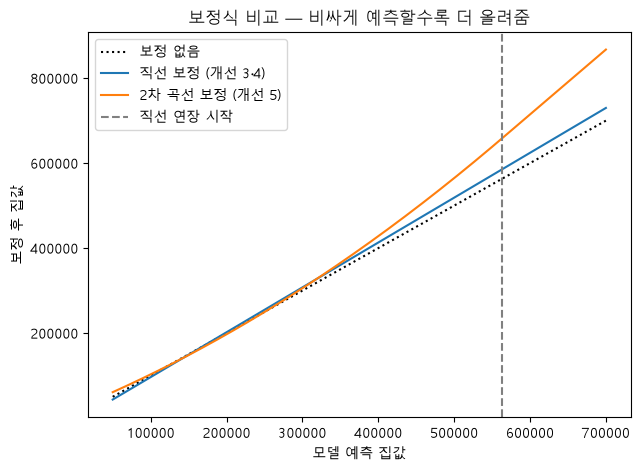

In [27]:
# 직선 보정 vs 2차 곡선 보정 — 예측값을 얼마나 바꾸는지 그래프로 확인
lin_cal = CalibratedRegressor(weighted_v4).fit(*drop_outliers(X, y))
quad_cal = QuadCalibratedRegressor(weighted_v4).fit(*drop_outliers(X, y))
c = quad_cal.calib_
print(f"직선 보정: 실제 ≈ {lin_cal.calib_.intercept_:,.0f} + {lin_cal.calib_.coef_[0]:.3f} × 예측")
print(f"2차 보정: 실제 ≈ {c.intercept_:,.0f} + {c.coef_[0]:.3f} × 예측 + {c.coef_[1]:.4f} × 예측² / 1,000,000")
print(f"직선 연장 시작점: 예측 {quad_cal.hi_:,.0f} 달러 이상")

grid = np.linspace(50000, 700000, 200)
lin_line = lin_cal.calib_.predict(grid.reshape(-1, 1))
quad_line = np.where(grid <= quad_cal.hi_, c.predict(quad_cal._f(np.minimum(grid, quad_cal.hi_))),
                     quad_cal.hi_val_ + quad_cal.slope_ * (grid - quad_cal.hi_))
plt.figure(figsize=(7, 5))
plt.plot(grid, grid, 'k:', label='보정 없음')
plt.plot(grid, lin_line, label='직선 보정 (개선 3·4)')
plt.plot(grid, quad_line, label='2차 곡선 보정 (개선 5)')
plt.axvline(quad_cal.hi_, color='gray', linestyle='--', label='직선 연장 시작')
plt.xlabel('모델 예측 집값'); plt.ylabel('보정 후 집값'); plt.legend()
plt.title('보정식 비교 — 비싸게 예측할수록 더 올려줌')
plt.show()

### 개선 6: 직선 보정과 2차 곡선 보정을 반씩 섞기

| 보정 | CV_RMSE (fold 분할 2가지 평균) | 실제 test RMSE |
|---|---|---|
| 직선 (개선 4) | 20,918 | 18,600대 |
| 2차 곡선 (개선 5) | 20,299 | 18,700대 |

CV에서는 2차 곡선이 좋았지만 test에서는 오히려 나빠졌습니다. 2차 곡선의 이득은 **표본이 적은 40만 달러 이상 집(21채)**에서 나오는데, test에는 그런 집이 적고 대신 중간 가격대 집을 조금 낮게 예측하는 손해가 드러났기 때문으로 보입니다.

두 보정은 **서로 다른 가격대에서 틀립니다** (직선 → 비싼 집, 2차 곡선 → 중간 가격대).
앙상블처럼 두 예측을 섞으면 오차가 일부 상쇄되어 둘 중 어느 쪽보다도 좋아질 수 있습니다.
- 두 제출 파일의 예측값 차이(RMS ≈ 6,700달러)와 두 test 점수로 계산하면, 오차가 가장 작아지는 비율은 **약 45~50%**
- CV에서도 50% 섞기(20,402)가 직선 보정(20,918)보다 좋음
- ⚠️ 섞는 비율은 CV가 아니라 **test 점수 2개를 참고해서** 정했습니다 (CV만 보면 2차 곡선 100%가 1위)

In [28]:
class MixCalibratedRegressor(QuadCalibratedRegressor):
    """직선 보정과 2차 곡선 보정을 w : (1 - w) 비율로 섞기 (원래 가격 단위에서)"""
    def __init__(self, estimator, cv=5, w=0.5):
        super().__init__(estimator, cv)
        self.w = w

    def fit(self, X, y):
        super().fit(X, y)   # 2차 곡선 보정 + 전체 모델 학습
        inner = KFold(n_splits=self.cv, shuffle=True, random_state=RANDOM_STATE)
        p = np.expm1(cross_val_predict(self.estimator, X, y, cv=inner))   # 같은 분할 → 같은 교차검증 예측
        self.lin_ = LinearRegression().fit(p.reshape(-1, 1), np.expm1(y))
        return self

    def predict(self, X):
        quad = np.expm1(super().predict(X))
        lin = self.lin_.predict(np.expm1(self.model_.predict(X)).reshape(-1, 1))
        return np.log1p(np.clip(self.w * lin + (1 - self.w) * quad, 1, None))

ensembles['가중 v4 + 보정 섞기 (직선 50% + 2차 50%)'] = MixCalibratedRegressor(weighted_v4, w=0.5)
record('4.개선6', '가중 v4 + 보정 섞기 (직선 50% + 2차 50%)', ensembles['가중 v4 + 보정 섞기 (직선 50% + 2차 50%)'])

가중 v4 + 보정 섞기 (직선 50% + 2차 50%) Val_RMSE =    18,047   CV_RMSE =    19,851 (± 1,831)


,단계,모델,Val_RMSE,CV_RMSE,CV_std
0,4.개선5,가중 v4 + 2차 곡선 보정,18090.0,19713.0,1725.0
1,4.개선6,가중 v4 + 보정 섞기 (직선 50% + 2차 50%),18047.0,19851.0,1831.0
2,4.개선4,가중 v4 + 예측값 보정,18317.0,20538.0,1825.0
3,4.개선3,가중 v3 + 예측값 보정,18804.0,20805.0,1787.0
4,4.개선4,가중 v4 (+SVR 30%),17219.0,20845.0,2398.0
5,4.개선3,가중 v3 (Lasso 재튜닝 + 0.2/0.4/0.4),17758.0,21084.0,2358.0
6,4.개선4,SVR,17312.0,21212.0,2376.0
7,3.앙상블,Stacking,18153.0,21369.0,2293.0
8,3.앙상블,가중(GBR+GBR원래+Lasso),18321.0,21434.0,2339.0
9,3.앙상블,Voting(선형+부스팅),18070.0,21890.0,2459.0


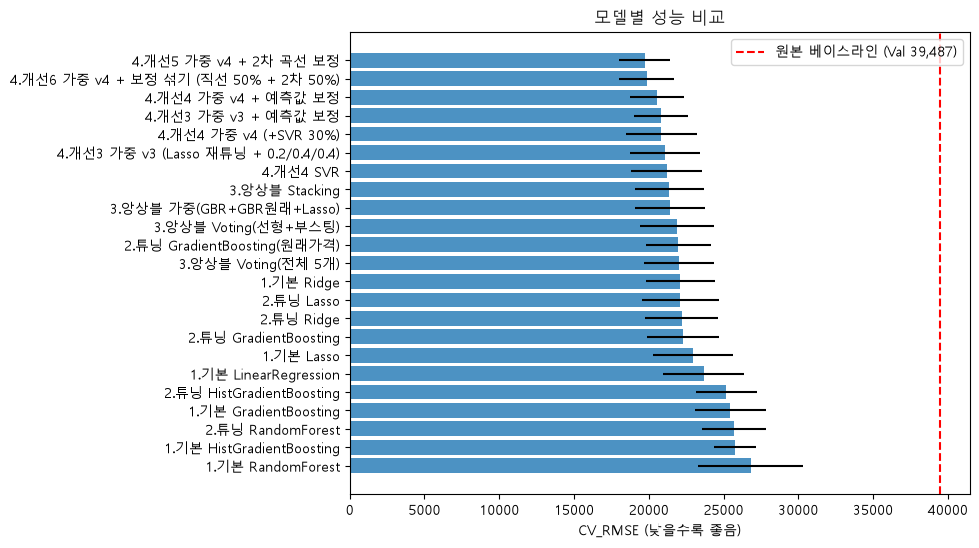

CV_RMSE 1위: 4.개선5 가중 v4 + 2차 곡선 보정
🏆 최종 선택: 4.개선6 가중 v4 + 보정 섞기 (직선 50% + 2차 50%)


In [29]:
# 전체 결과 비교
result_df = pd.DataFrame(results).sort_values('CV_RMSE').reset_index(drop=True)
display(result_df.round(0))

plot_df = result_df.sort_values('CV_RMSE', ascending=False)
plt.figure(figsize=(8, 6))
plt.barh(plot_df['단계'] + ' ' + plot_df['모델'], plot_df['CV_RMSE'], xerr=plot_df['CV_std'], alpha=0.8)
plt.axvline(39487, color='red', linestyle='--', label='원본 베이스라인 (Val 39,487)')
plt.xlabel('CV_RMSE (낮을수록 좋음)'); plt.legend(); plt.title('모델별 성능 비교')
plt.show()

all_models = {**{f'1.기본 {k}': v for k, v in base_models.items()},
              **{f'2.튜닝 {k}': v for k, v in tuned.items()},
              '2.튜닝 GradientBoosting(원래가격)': gbr_raw,
              **{f'3.앙상블 {k}': v for k, v in ensembles.items()},
              **{f'4.개선3 {k}': v for k, v in ensembles.items()},
              **{f'4.개선4 {k}': v for k, v in ensembles.items()},
              **{f'4.개선5 {k}': v for k, v in ensembles.items()},
              **{f'4.개선6 {k}': v for k, v in ensembles.items()},
              '4.개선4 SVR': svr}
best_key = result_df.loc[0, '단계'] + ' ' + result_df.loc[0, '모델']
best_model = all_models[best_key]
print('CV_RMSE 1위:', best_key)

# CV만 보면 2차 곡선 보정(개선 5)이 1위지만, 실제 test에서는 직선 보정(개선 4)보다 나빴음
# → 두 보정을 반씩 섞은 개선 6을 최종 모델로 선택 (선택 근거는 '개선 6' 설명 참고)
best_key = '4.개선6 가중 v4 + 보정 섞기 (직선 50% + 2차 50%)'
best_model = all_models[best_key]
print('🏆 최종 선택:', best_key)

### 테스트 데이터 예측 및 제출

In [30]:
# 최종 모델을 train 전체로 다시 학습 → test 예측 (log → 원래 가격으로 되돌리기)
Xa, ya = drop_outliers(X, y) if REMOVE_OUTLIERS else (X, y)
final_model = clone(best_model).fit(Xa, ya)
test_pred = np.expm1(final_model.predict(X_test))

print(pd.Series(test_pred).describe().round(0))   # 음수나 터무니없는 값이 없는지 확인

count       292.0
mean     181524.0
std       78926.0
min       59983.0
25%      129973.0
50%      160356.0
75%      215683.0
max      636070.0
dtype: float64


In [31]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_pred
})
# 기존 submission.csv를 덮어쓰지 않도록 다른 이름으로 저장
submission.to_csv("submission_improved6.csv", index=False)
submission.head()

,Id,SalePrice
0,86,275735.099734
1,227,282203.022318
2,492,143703.203687
3,64,134614.951908
4,576,114083.443713


### 정리

| 항목 | 원본 | 개선 |
|---|---|---|
| 결측치 | 전부 중앙값/최빈값 | '없음' 의미 반영 + train 기준 대체 |
| 이상치 | 그대로 | 학습에서 2채 제거 (test에 없는 유형) |
| 인코딩 | train/test 따로 → 컬럼 의미 불일치 | 합쳐서 한 번에 + 품질 등급은 숫자로 |
| 새 피처 | 없음 | 총면적, 욕실 수, 집 나이, 품질 × 면적 |
| 타깃 | 원래 가격 | log 변환 후 학습 (+ 원래 가격 모델과 섞기) |
| log 변환 | 없음 | 왜도 1.0 초과 컬럼만 (0이 많은 컬럼·등급은 제외) |
| 모델 | LinearRegression 1개 | 7개 비교(+SVR) + 튜닝 + 앙상블 |
| 튜닝 기준 | 없음 | 실제 평가지표(원래 가격 RMSE)로 재튜닝, 다른 fold 분할로 과적합 확인 |
| 예측 보정 | 없음 | 비싼 집을 싸게 예측하는 쏠림을 교차검증 기반 선형 보정으로 완화 |
| 평가 | validation 1번 | validation + 5-fold CV (test 상황에 맞춰 이상치 제외 채점) |

위 결과 표에서 원본 Val_RMSE(≈ 39,487)와 개선 모델의 Val_RMSE / CV_RMSE를 비교해보세요.

**개선 5**: 예측값 보정을 직선 → 2차 곡선(외삽 안전장치 포함)으로 바꿔 고가 주택의 과소예측을 줄임. → CV는 좋아졌지만 실제 test는 18,700대로 악화.

**개선 6**: 직선 보정과 2차 곡선 보정을 50%씩 섞어, 두 보정의 서로 다른 오차를 상쇄. 섞는 비율은 test 점수 2개를 참고해 정했음.